In [2]:
!pip install -q albumentations timm transformers torchmetrics

In [7]:
import sys, os
sys.path.append(os.path.join(os.getcwd(), "scripts"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import DataLoader
from transformers import AutoTokenizer
import torch
from scripts.config import Config
from scripts.dataset import DishDataset, get_dataloaders, get_transforms, get_test_loader
from scripts.utils import train, load_model, evaluate
print(torch.cuda.is_available())

True


#1. Загрузка данных и EDA

## 1.1 Загрузка и первичный осмотр

Загружены два файла: dish.csv с 3262 блюдами и ingredients.csv со справочником из 555 ингредиентов.

In [8]:
dish = pd.read_csv("data/dish.csv")
ingr = pd.read_csv("data/ingredients.csv")

print("dish:", dish.shape)
print(dish.dtypes)
dish.head()

dish: (3262, 5)
dish_id            object
total_calories    float64
total_mass        float64
ingredients        object
split              object
dtype: object


,dish_id,total_calories,total_mass,ingredients,split
0,dish_1561662216,300.794281,193.0,ingr_0000000508;ingr_0000000122;ingr_000000002...,test
1,dish_1561662054,419.438782,292.0,ingr_0000000312;ingr_0000000026;ingr_000000002...,train
2,dish_1562008979,382.936646,290.0,ingr_0000000448;ingr_0000000520;ingr_000000046...,test
3,dish_1560455030,20.590000,103.0,ingr_0000000471;ingr_0000000031;ingr_0000000347,train
4,dish_1558372433,74.360001,143.0,ingr_0000000453,train


In [9]:
print("ingredients:", ingr.shape)
print(ingr.dtypes)
ingr.head()

ingredients: (555, 2)
id       int64
ingr    object
dtype: object


,id,ingr
0,1,cottage cheese
1,2,strawberries
2,3,garden salad
3,4,bacon
4,5,potatoes


Датасет разделен на train (2755) и test (507) в соотношении примерно 85/15, метка split задана заранее.

In [10]:
print(dish['split'].value_counts())

split
train    2755
test      507
Name: count, dtype: int64


## 1.2 Пропуски, дубликаты

Пропуски в загруженных таблицах отсутствуют.

In [11]:
ingr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 555 entries, 0 to 554
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      555 non-null    int64 
 1   ingr    555 non-null    object
dtypes: int64(1), object(1)
memory usage: 8.8+ KB


In [12]:
dish.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3262 entries, 0 to 3261
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   dish_id         3262 non-null   object 
 1   total_calories  3262 non-null   float64
 2   total_mass      3262 non-null   float64
 3   ingredients     3262 non-null   object 
 4   split           3262 non-null   object 
dtypes: float64(2), object(3)
memory usage: 127.6+ KB


Дубликатов в таблице dish не обнаружено. В таблице ingr найдено 3 дубликата (по названию ингредиентов).

In [13]:
print("Дубликаты dish:", dish.duplicated().sum())
print("Дубликаты ingr:", ingr['ingr'].duplicated().sum(), "\n")

Дубликаты dish: 0
Дубликаты ingr: 3 



Все три найденных в справочнике ингредиентов дубликата оказались служебной меткой deprecated, присвоенной разным id, реальных дублей продуктов нет.

In [14]:
dups = ingr.loc[ingr['ingr'].duplicated(), 'ingr'].unique().tolist()
print("Дубликаты ingr:", *dups)

Дубликаты ingr: deprecated


## 1.3 Объединение таблиц

Технические идентификаторы ингредиентов заменены на читаемые названия через словарь id2name, сформированный приведением id к формату ingr_XXXXXXXXXX.

In [15]:
ingr['key'] = 'ingr_' + ingr['id'].astype(str).str.zfill(10)
id2name = dict(zip(ingr['key'], ingr['ingr']))

dish['ingredients'] = dish['ingredients'].apply(
    lambda s: ', '.join(id2name[i] for i in s.split(';'))
)

dish.head()

,dish_id,total_calories,total_mass,ingredients,split
0,dish_1561662216,300.794281,193.0,"soy sauce, garlic, white rice, parsley, onions...",test
1,dish_1561662054,419.438782,292.0,"pepper, white rice, mixed greens, garlic, soy ...",train
2,dish_1562008979,382.936646,290.0,"jalapenos, lemon juice, pork, wheat berry, cab...",test
3,dish_1560455030,20.590000,103.0,"cherry tomatoes, cucumbers, baby carrots",train
4,dish_1558372433,74.360001,143.0,deprecated,train


Полученный в результате объединения датасет содержит 3262 записи без пропусков: два числовых признака (total_calories, total_mass) и три категориальных (dish_id, ingredients, split).

In [16]:
dish.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3262 entries, 0 to 3261
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   dish_id         3262 non-null   object 
 1   total_calories  3262 non-null   float64
 2   total_mass      3262 non-null   float64
 3   ingredients     3262 non-null   object 
 4   split           3262 non-null   object 
dtypes: float64(2), object(3)
memory usage: 127.6+ KB


## 1.4 Обработка служебных меток в справочнике ингредиентов

В датасете 31 строка содержит служебную метку depricated. Разброс по калоийности широкий.

In [17]:
deprecated = dish[dish['ingredients'].str.contains('deprecated')]
print(f"Количество записей, содержащих заглушку 'deprecated': {len(deprecated)}")

Количество записей, содержащих заглушку 'deprecated': 31


In [18]:
deprecated.describe()

,total_calories,total_mass
count,31.000000,31.000000
mean,230.255260,193.580645
std,281.291034,97.057294
min,12.300000,41.000000
25%,74.099998,143.000000
50%,74.879997,144.000000
75%,261.757492,307.500000
max,1148.250977,374.000000


Визуализация всех 31 блюд со служебной меткой для оценки возможности ручного восстановления состава по фотографиям.

In [19]:
fig, axes = plt.subplots(6, 6, figsize=(22, 22))
for ax, (_, r) in zip(axes.flat, deprecated.iterrows()):
    ax.imshow(Image.open(f"data/images/{r['dish_id']}/rgb.png").convert("RGB"))
    ax.set_title(f"{r['dish_id']}\n{r['ingredients'][:70]}", fontsize=7)
    ax.axis("off")

for ax in axes.flat[len(deprecated):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

На фотографиях всех 31 блюда явно различимы яблоки, в отдельных случаях арбузы. Это подтверждает, что служебная метка соответствует реальным продуктам, и состав можно восстановить вручную. Перед заменой проверим, встречаются ли apple и watermelon в справочнике ингредиентов.

In [20]:
ingr[ingr['ingr'].str.contains('apple|watermelon', case=False, na=False)][['id', 'ingr']]

,id,ingr
37,38,pineapple
53,54,apple
84,85,apple juice
120,121,watermelon
158,159,apple cider
174,175,apple pie
502,503,applesauce
509,510,chicken apple sausage


В справочнике присутствуют оба продукта: apple (id 54) и watermelon (id 121). Это подтверждает, что метка deprecated соответствовала этим ингредиентам, и состав можно восстановить, используя существующие названия.

In [21]:
manual_fix = {
    'dish_1558372433': 'apple', 'dish_1558114086': 'apple', 'dish_1558027001': 'watermelon', 'dish_1558373159': 'apple', 'dish_1558115364': 'apple',
    'dish_1558114875': 'apple', 'dish_1558375506': 'apple', 'dish_1558028142': 'watermelon', 'dish_1558031019': 'watermelon', 'dish_1558030724': 'watermelon',
    'dish_1558109945': 'apple', 'dish_1558027243': 'watermelon', 'dish_1558373074': 'apple', 'dish_1558379876': 'apple', 'dish_1558115282': 'apple',
    'dish_1558379588': 'apple', 'dish_1558376984': 'apple', 'dish_1558028606': 'watermelon', 'dish_1558122740': 'apple', 'dish_1558116547': 'apple',
    'dish_1558115047': 'apple', 'dish_1558380152': 'apple', 'dish_1558375583': 'apple', 'dish_1558031394': 'watermelon', 'dish_1558114284': 'apple',
    'dish_1558028772': 'watermelon', 'dish_1558031351': 'watermelon', 'dish_1558376768': 'apple', 'dish_1558372771': 'apple', 'dish_1558380181': 'apple',
    'dish_1558028194': 'watermelon'
}
for dish_id, replacement in manual_fix.items():
    mask = dish['dish_id'] == dish_id
    dish.loc[mask, 'ingredients'] = dish.loc[mask, 'ingredients'].str.replace('deprecated', replacement)

print("Осталось 'deprecated':", dish['ingredients'].str.contains('deprecated').sum())

Осталось 'deprecated': 0


Все 31 блюдо со служебной меткой проверены: deprecated успешно заменен на apple или watermelon в соответствии с содержимым фотографий. В текстовой компоненте метка больше не встречается.

In [22]:
fixed = dish[dish['dish_id'].isin(manual_fix.keys())].reset_index(drop=True)

fig, axes = plt.subplots(6, 6, figsize=(22, 22))
for ax, (_, r) in zip(axes.flat, fixed.iterrows()):
    ax.imshow(Image.open(f"data/images/{r['dish_id']}/rgb.png").convert("RGB"))
    ax.set_title(f"{r['dish_id']}\n{r['ingredients'][:70]}", fontsize=7)
    ax.axis("off")

for ax in axes.flat[len(fixed):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

## 1.5 Проверка распределений на аномалии

Описательная статистика датасета dish: средняя калорийность 255 ккал при медиане 209 ккал, что указывает на правостороннюю асимметрию. Минимум 0 ккал и максимум 3943 ккал свидетельствуют о наличии выбросов.

In [23]:
dish[['total_calories', 'total_mass']].describe()

,total_calories,total_mass
count,3262.000000,3262.000000
mean,255.012738,214.980074
std,219.637570,161.497428
min,0.000000,1.000000
25%,80.114996,92.000000
50%,209.110062,177.000000
75%,375.122963,305.000000
max,3943.325195,3051.000000


Гистограммы калорийности и массы визуально подтверждают правостороннюю форму распределений с длинным хвостом.

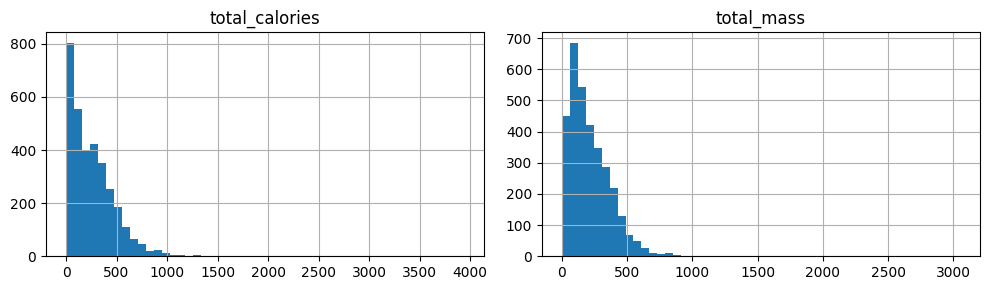

In [24]:
dish[['total_calories', 'total_mass']].hist(bins=50, figsize=(10, 3), layout=(1, 2))
plt.tight_layout()
plt.show()

Квантильное распределение показывает, что 99% блюд укладываются в диапазон до 919 ккал и 702 г, а оставшийся 1% формирует длинный правый хвост.

In [25]:
quantiles = [0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]
dish[['total_calories', 'total_mass']].quantile(quantiles).round(1)

,total_calories,total_mass
0.001,1.9,5.3
0.010,6.4,14.0
0.050,19.1,36.0
0.250,80.1,92.0
0.500,209.1,177.0
0.750,375.1,305.0
0.950,646.8,500.0
0.990,918.5,702.3
0.999,1257.6,927.6


Обнаружены 2 блюда с 0 ккал - обе записи содержат только метку plate only и представляют собой фотографии пустых тарелок, а не реальные блюда.

In [26]:
zero = dish[dish['total_calories'] == 0]
print(len(zero), "блюд с 0 ккал")
print(zero[['dish_id', 'total_mass', 'ingredients']].head(10))

2 блюд с 0 ккал
              dish_id  total_mass ingredients
263   dish_1557861216         1.0  plate only
2652  dish_1556575700        86.0  plate only


Обнаружено одно блюдо с калорийностью 3943 ккал и массой 3051 г - рекордный выброс с реальным составом ингредиентов.

In [27]:
max = dish[dish['total_calories'] >= 3943]
print(len(max), "блюд с 3943 ккал")
print(max['ingredients'].tolist())
max[['dish_id', 'total_mass', 'ingredients']]

1 блюд с 3943 ккал
['spinach (raw), tortilla chips, corn, cheese, white rice, cherry tomatoes, lime, tomatoes, chili, garlic, salt, sour cream, onions, black beans']


,dish_id,total_mass,ingredients
1518,dish_1560974769,3051.0,"spinach (raw), tortilla chips, corn, cheese, w..."


Удалены 2 записи plate only с 0 ккал и 1 аномальный выброс в 3943 ккал - итого 3 блюда, осталось 3259.

In [28]:
before = len(dish)
dish = dish[(dish['total_calories'] > 0) & (dish['total_calories'] < 3943)].reset_index(drop=True)
print(f"Удалено {before - len(dish)}, осталось {len(dish)}")

Удалено 3, осталось 3259


## 1.6 Корреляция массы и калорийности

Корреляция массы и калорийности составила 0.736 по Пирсону и 0.781 по Спирмену, что указывает на сильную монотонную связь. Масса объясняет около половины дисперсии целевой переменной (квадрат корреляции пирсона = 0.54). Оставшаяся часть разброса определяется составом блюда, поэтому масса используется как дополнительный признак, но не заменяет визуальную и текстовую модальности

In [29]:
pearson = dish['total_calories'].corr(dish['total_mass'], method='pearson')
spearman = dish['total_calories'].corr(dish['total_mass'], method='spearman')
r2 = pearson ** 2

print(f"Пирсон: {pearson:.3f}")
print(f"Спирмен: {spearman:.3f}")
print(f"Квадрат корреляции Пирсона: {r2:.3f}")

Пирсон: 0.736
Спирмен: 0.781
Квадрат корреляции Пирсона: 0.541


## 1.7 Визуализация и проверка изображений

Для каждого dish_id найдена соответствующая папка с rgb.png - пропущенных изображений нет.

In [30]:
missing = [d for d in dish['dish_id'] if not os.path.exists(f"data/images/{d}/rgb.png")]
print("Без картинок:", len(missing))

Без картинок: 0


### 1.7.1 Примеры изображений

Примеры случайных блюд из датасета с указанием калорийности - для визуальной оценки разнообразия и условий съемки.

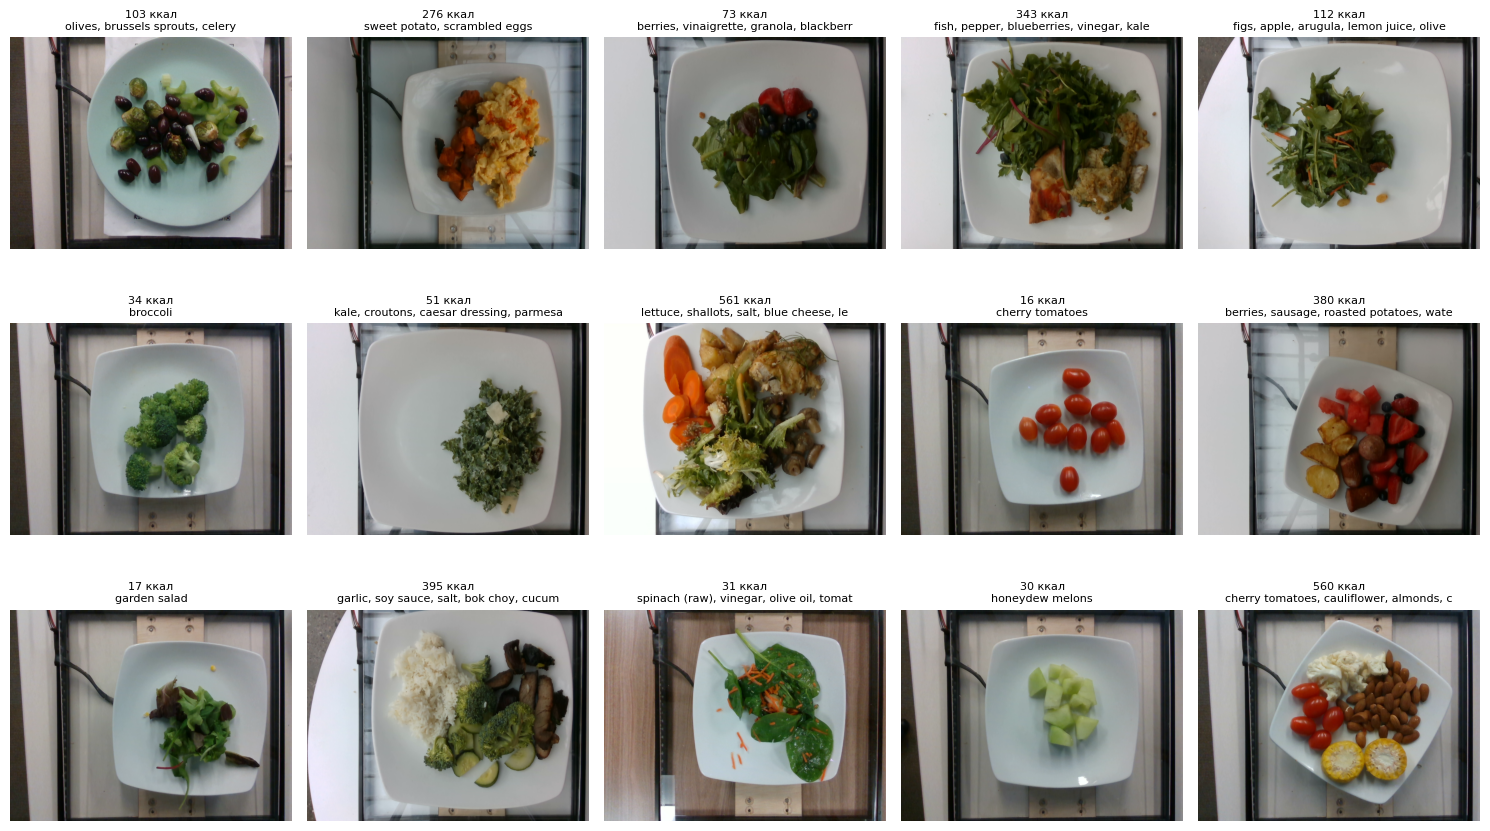

In [31]:
fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for ax, (_, r) in zip(axes.flat, dish.sample(15, random_state=42).iterrows()):
    ax.imshow(Image.open(f"data/images/{r['dish_id']}/rgb.png").convert("RGB"))
    ax.set_title(f"{r['total_calories']:.0f} ккал\n{r['ingredients'][:40]}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

Примеры пяти самых легких и пяти самых калорийных блюд - для проверки, различаются ли они визуально и соответствует ли калорийность составу.

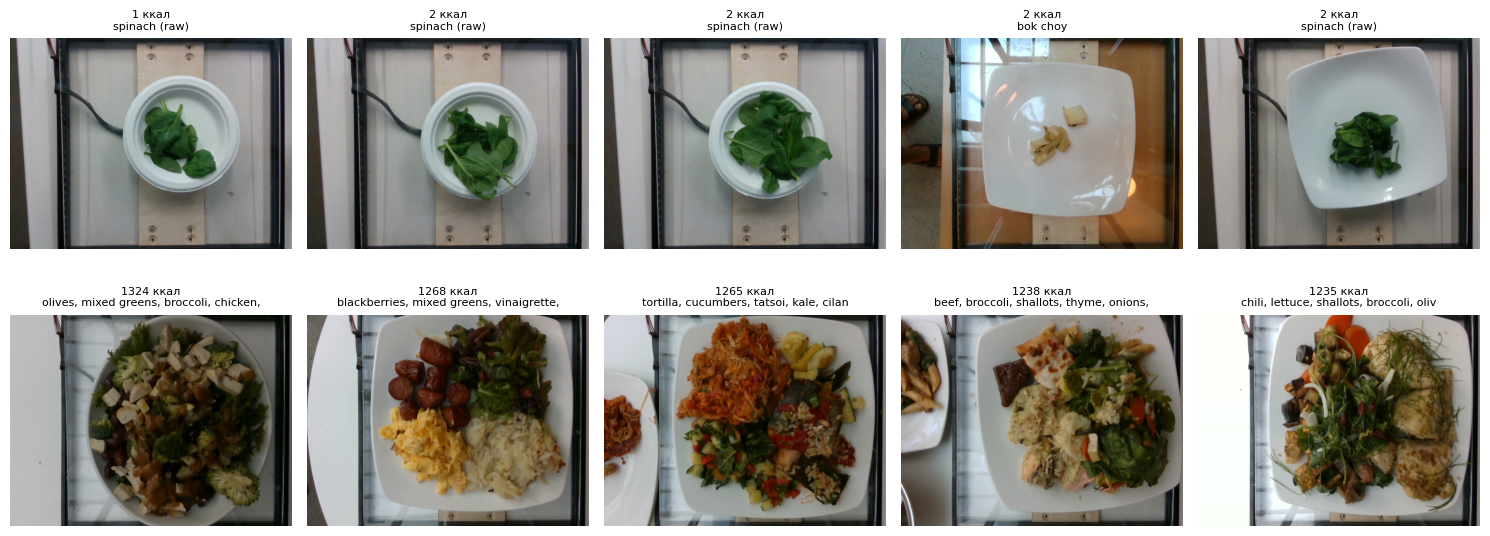

In [32]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
sample = pd.concat([dish.nsmallest(5, 'total_calories'),
                    dish.nlargest(5, 'total_calories')])

for ax, (_, r) in zip(axes.flat, sample.iterrows()):
    ax.imshow(Image.open(f"data/images/{r['dish_id']}/rgb.png").convert("RGB"))
    ax.set_title(f"{r['total_calories']:.0f} ккал\n{r['ingredients'][:40]}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

Блюда сняты сверху на нейтральном фоне в одинаковом ракурсе, но тарелки разного размера, поэтому модель может выучить размер посуды как косвенный признак порции. Для снижения этого риска в аугментации планируется добавить RandomResizedCrop, который меняет масштаб объектов и заставляет модель опираться на содержимое тарелки, а не на ее границы.

### 1.7.2 Размеры, яркость и контрастность изображений

Все изображения имеют одинаковый размер 640х480 - датасет унифицирован, дополнительная проверка пропорций не требуется.

In [33]:
sizes = [Image.open(f"data/images/{d}/rgb.png").size for d in dish['dish_id']]
pd.Series(sizes).value_counts()

,count
"(640, 480)",3259


Все изображения в режиме RGB - дополнительная конвертация при загрузке не требуется.

In [34]:
modes = [Image.open(f"data/images/{d}/rgb.png").mode for d in dish['dish_id']]
pd.Series(modes).value_counts()

,count
RGB,3259


Изображения однородны по освещению: средняя яркость 0.465, стандартное отклонение 0.058, минимум 0.295, максимум 0.689. Контраст в среднем 0.232, минимум 0.130, максимум 0.375.

In [35]:
stats = []
for d in dish['dish_id']:
    arr = np.array(Image.open(f"data/images/{d}/rgb.png").convert("RGB")) / 255
    stats.append([arr.mean(), arr.std()])

pd.DataFrame(stats, columns=['brightness', 'contrast']).describe().round(3)

,brightness,contrast
count,3259.000,3259.000
mean,0.465,0.232
std,0.058,0.035
min,0.295,0.130
25%,0.428,0.207
50%,0.459,0.227
75%,0.489,0.255
max,0.689,0.375


Распределения яркости и контраста близки к нормальным, но не симметричны: у яркости заметен правый хвост (медиана 0.458, максимум 0.689 - группа светлых кадров), у контраста - слабый левый хвост (минимум 0.130 при 25-м перцентиле 0.207 - группа пониженного контраста). Явных выбросов нет, значения лежат в узком диапазоне, но небольшая неоднородность по освещению присутствует.



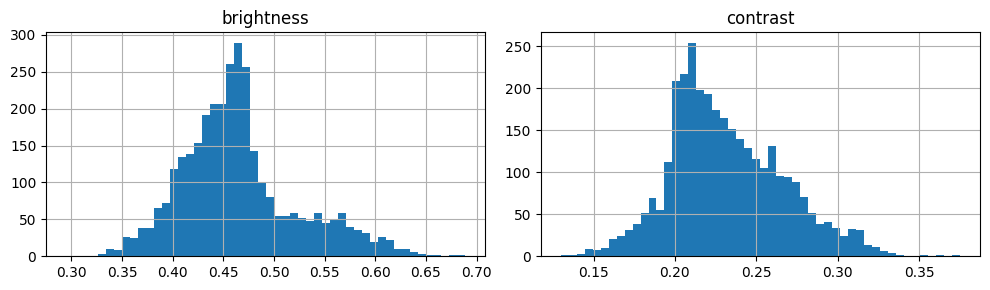

In [36]:
df = pd.DataFrame(stats, columns=['brightness', 'contrast'])
df.hist(bins=50, figsize=(10, 3), layout=(1, 2))
plt.tight_layout()
plt.show()

## 1.8 Выводы и подход к решению

Датасет содержит изображения, текстовые описания состава и массу порции, целевая переменная калорийность. Задача формулируется как мультимодальная регрессия: по трем входам (описание, изображения и масса) предсказать одно число. Масса подается как дополнительный числовой признак, но не заменяет картинку и текст, так как сама по себе объясняет лишь часть разброса калорийности.

Архитектура включает два предобученных энкодера, проекции в общее пространство, конкатенацию проекций с нормализованной массой и регрессионную голову. Масса нормализуется через логарифм и стандартизацию, затем проецируется в то же пространство, что текст и изображение, чтобы вклады всех трех модальностей были соизмеримы. Конкатенации достаточно: модальности равноправны и не требуют взаимодействия на уровне последовательностей. Целевая метрика MAE, дополнительно отслеживается динамика на train и val и анализируются худшие предсказания.

В пайплайне обучения планируется использовать базовые аугментации изображений: приведение к нужному размеру, нормализацию и горизонтальное отражение. Дополнительно добавляется случайный кроп, чтобы модель не привязывалась к размеру тарелки как косвенному признаку порции. Поскольку по яркости и контрасту изображения близки к нормальным, но имеют слабые хвосты, добавляется легкий ColorJitter по яркости и контрасту. Это не устраняет сами хвосты, но делает модель устойчивее к редким светлым и низкоконтрастным кадрам без риска исказить информативные цветовые признаки блюд.

# 2. Обучение модели

In [37]:
cfg = Config()
model, mass_mean, mass_std, test_df = train(cfg, dish)

Device: cuda
mass_mean=5.105, mass_std=0.820


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1/12 | train_loss 102.45 | val_mae 64.56
  saved: checkpoints/best.pt
epoch 2/12 | train_loss 64.41 | val_mae 56.47
  saved: checkpoints/best.pt
epoch 3/12 | train_loss 57.58 | val_mae 50.96
  saved: checkpoints/best.pt
epoch 4/12 | train_loss 49.84 | val_mae 48.59
  saved: checkpoints/best.pt
epoch 5/12 | train_loss 48.26 | val_mae 42.86
  saved: checkpoints/best.pt
epoch 6/12 | train_loss 45.01 | val_mae 45.01
epoch 7/12 | train_loss 42.22 | val_mae 39.52
  saved: checkpoints/best.pt
epoch 8/12 | train_loss 41.64 | val_mae 46.39
epoch 9/12 | train_loss 39.21 | val_mae 54.60
epoch 10/12 | train_loss 38.30 | val_mae 34.98
  saved: checkpoints/best.pt
epoch 11/12 | train_loss 36.35 | val_mae 34.59
  saved: checkpoints/best.pt
epoch 12/12 | train_loss 36.39 | val_mae 37.62
Best val MAE: 34.59


## Динамика обучения

За 12 эпох модель показала устойчивое снижение val_mae с 64.56 до 34.59. Наблюдались колебания на эпохах 6, 8, 9 (волатильность из-за малого размера val-выборки), но общий тренд - падение. Лучший чекпоинт сохранен на эпохе 11 со значением val_mae = 34.59, он и используется для финального инференса.

In [38]:
with open(cfg.LOG_PATH) as f:
    print(f.read())

epoch 1/12 | train_loss 102.45 | val_mae 64.56
epoch 2/12 | train_loss 64.41 | val_mae 56.47
epoch 3/12 | train_loss 57.58 | val_mae 50.96
epoch 4/12 | train_loss 49.84 | val_mae 48.59
epoch 5/12 | train_loss 48.26 | val_mae 42.86
epoch 6/12 | train_loss 45.01 | val_mae 45.01
epoch 7/12 | train_loss 42.22 | val_mae 39.52
epoch 8/12 | train_loss 41.64 | val_mae 46.39
epoch 9/12 | train_loss 39.21 | val_mae 54.60
epoch 10/12 | train_loss 38.30 | val_mae 34.98
epoch 11/12 | train_loss 36.35 | val_mae 34.59
epoch 12/12 | train_loss 36.39 | val_mae 37.62



# 3. Инференс обученной модели и валидация качества

In [39]:
model, mass_mean, mass_std = load_model(cfg)
print(f"Loaded model, mass_mean={mass_mean:.3f}, mass_std={mass_std:.3f}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loaded model, mass_mean=5.105, mass_std=0.820


## 3.1 Финальная метрика

Test MAE = 39.40 ккал при требовании MAE < 50. Разница с лучшим val_mae (34.59) около 5 ккал - ожидаемо из-за меньшего размера val-выборки. Метрика подтверждает обобщающую способность модели.

In [40]:
tokenizer = AutoTokenizer.from_pretrained(cfg.TEXT_MODEL_NAME)
test_loader = get_test_loader(cfg, test_df, tokenizer, mass_mean, mass_std)

test_mae, preds, targets = evaluate(model, test_loader, cfg)
print(f"Test MAE: {test_mae:.2f}")

Test MAE: 39.40


## 3.2 Анализ худших предсказаний

Пять худших примеров имеют ошибки 441, 413, 349, 329 и 313 ккал. Все они относятся к высококалорийным блюдам (реальная калорийность выше 700 ккал), в большинстве присутствует миндаль в разных количествах. Модель систематически недооценивает такие блюда. Причины: длинный правый хвост распределения (99% блюд ниже 919 ккал, высококалорийные примеры редки в train), отсутствие информации о количестве ингредиентов в тексте, нестандартные размеры порций. Эти ошибки не влияют критично на общую метрику MAE = 39.40, но указывают на направление для улучшения: взвешивание лосса по калорийности, oversampling высококалорийных блюд, добавление массы ингредиентов.

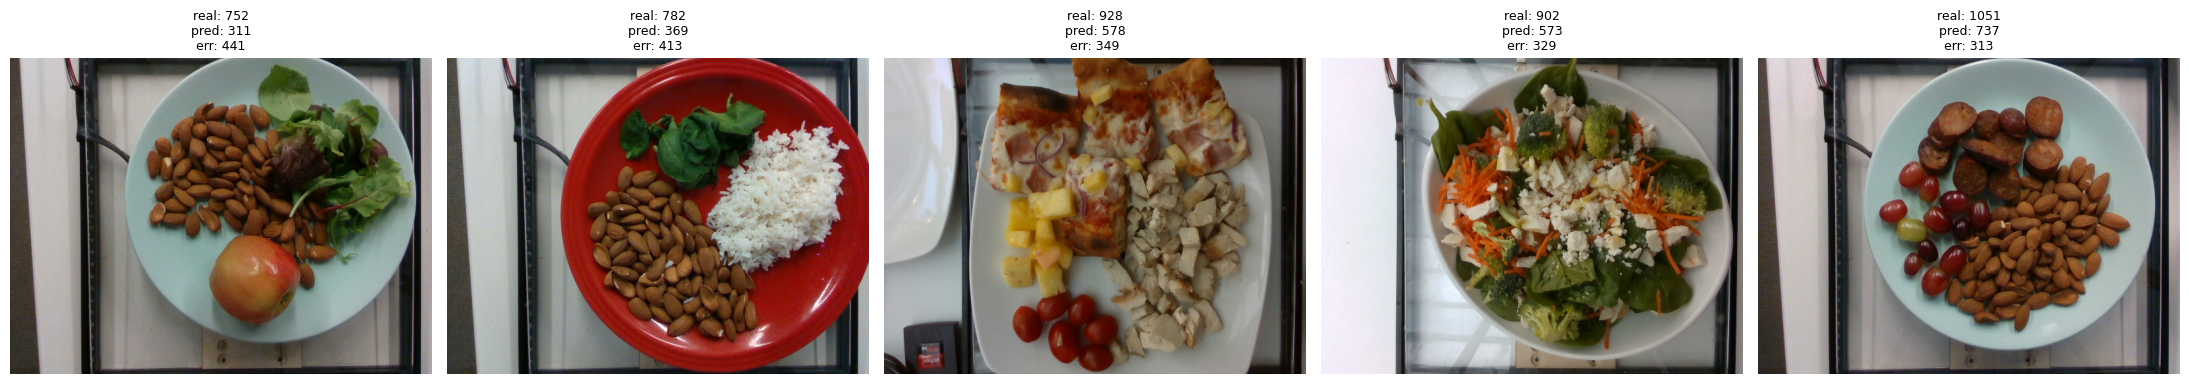

dish_1558630325 | real 752, pred 311, err 441.0, mass 269 г
  apple, garden salad, almonds

dish_1558549806 | real 782, pred 369, err 413.0, mass 203 г
  almonds, white rice, spinach (raw)

dish_1566328805 | real 928, pred 578, err 349.3, mass 488 г
  cherry tomatoes, pizza, chicken, pineapple

dish_1565811139 | real 902, pred 573, err 328.7, mass 416 г
  carrot, goat cheese, olive oil, broccoli, spinach (raw), chicken

dish_1558375886 | real 1051, pred 737, err 313.3, mass 277 г
  almonds, sausage, grapes



In [43]:
errors = np.abs(preds - targets)
worst_idx = errors.argsort()[::-1][:5]

fig, axes = plt.subplots(1, 5, figsize=(22, 5))
for ax, idx in zip(axes, worst_idx):
    row = test_df.iloc[idx]
    ax.imshow(Image.open(f"data/images/{row['dish_id']}/rgb.png").convert("RGB"))
    ax.set_title(f"real: {targets[idx]:.0f}\npred: {preds[idx]:.0f}\nerr: {errors[idx]:.0f}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

for idx in worst_idx:
    row = test_df.iloc[idx]
    print(f"{row['dish_id']} | real {targets[idx]:.0f}, pred {preds[idx]:.0f}, err {errors[idx]:.1f}, mass {row['total_mass']:.0f} г")
    print(f"  {row['ingredients']}")
    print()

## 3.3 Анализ лучших предсказаний

Все пять примеров - низкокалорийные блюда (32-74 ккал) с массой 34-142 г и одним-двумя простыми ингредиентами. Ошибка менее 0.5 ккал. Модель точно предсказывает такие случаи, потому что они просты, типичны и хорошо представлены в обучающей выборке. Здесь сигнал от текста и массы однозначен, визуальные признаки не противоречат описанию.

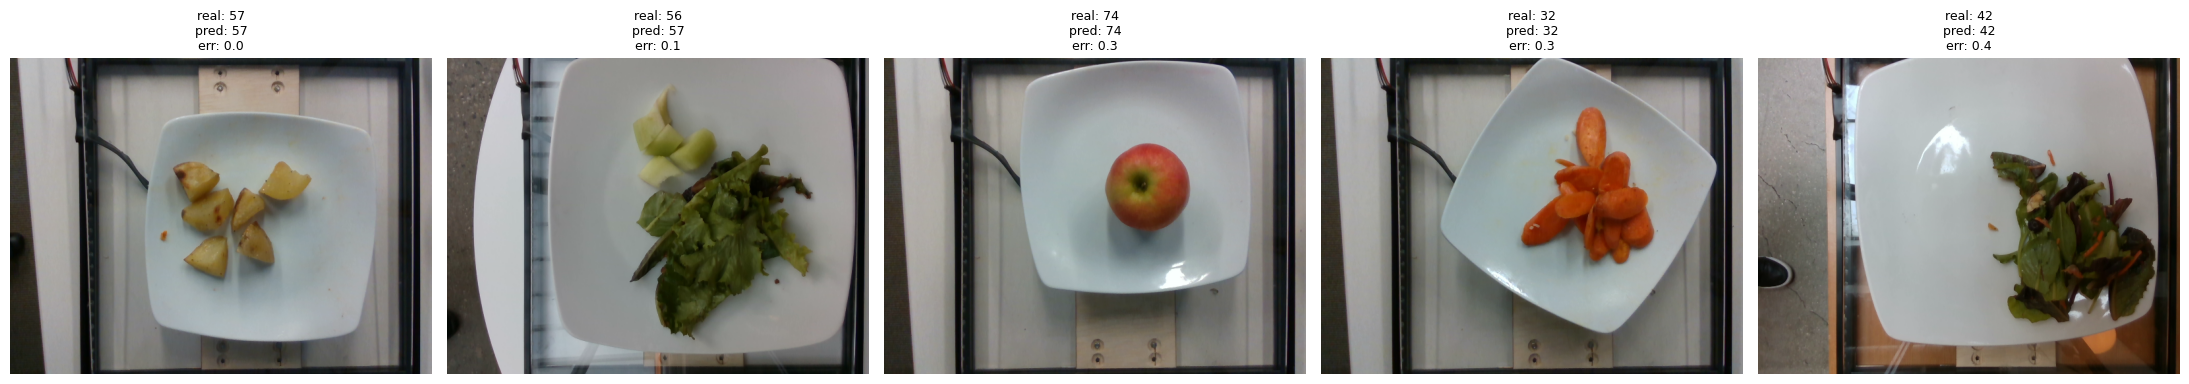

dish_1558031302 | real 57, pred 57, err 0.0, mass 74 г
  potatoes

dish_1562168673 | real 56, pred 57, err 0.1, mass 73 г
  mixed greens, blackberries, raspberries, honeydew melons, vinaigrette, granola

dish_1558545738 | real 74, pred 74, err 0.3, mass 142 г
  apple

dish_1558639526 | real 32, pred 32, err 0.3, mass 78 г
  carrot

dish_1561147944 | real 42, pred 42, err 0.4, mass 34 г
  olive oil, mustard, carrot, salt, raspberries, almonds, arugula, vinegar, chard, blueberries



In [42]:
errors = np.abs(preds - targets)
best_idx = errors.argsort()[:5]

fig, axes = plt.subplots(1, 5, figsize=(22, 5))
for ax, idx in zip(axes, best_idx):
    row = test_df.iloc[idx]
    ax.imshow(Image.open(f"data/images/{row['dish_id']}/rgb.png").convert("RGB"))
    ax.set_title(f"real: {targets[idx]:.0f}\npred: {preds[idx]:.0f}\nerr: {errors[idx]:.1f}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

for idx in best_idx:
    row = test_df.iloc[idx]
    print(f"{row['dish_id']} | real {targets[idx]:.0f}, pred {preds[idx]:.0f}, err {errors[idx]:.1f}, mass {row['total_mass']:.0f} г")
    print(f"  {row['ingredients']}")
    print()

# 4. Заключение

Построена мультимодальная модель для предсказания калорийности блюд: DistilBERT обрабатывает текст ингредиентов, ResNet18 - изображение, отдельная проекция приводит массу в общее пространство. Все три представления объединяются конкатенацией, поверх стоит регрессионная голова. На тестовой выборке достигнут MAE 39.40 ккал, что укладывается в требование MAE < 50. Модель отлично справляется с типичными низкокалорийными блюдами (ошибка меньше 1 ккал), но недооценивает высококалорийные блюда с редкими сочетаниями ингредиентов вроде миндаля - ошибки там достигают 300-440 ккал. Основные ограничения связаны с длинным правым хвостом распределения и отсутствием информации о количестве ингредиентов в тексте. Направления улучшения: взвешивание лосса по калорийности, добавление массы ингредиентов в описание, увеличение val-выборки и кросс-модальное внимание для сложных случаев.

In [52]:
!git status

On branch main
Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   .gitignore
	modified:   notebook.ipynb

no changes added to commit (use "git add" and/or "git commit -a")
